1. Annual Distribution of Funding Status in BC Publications

In [1]:
# ============================================================
# Import
# ============================================================

import pandas as pd
import ast

In [2]:
# ------------------------------------------------------------
# Load dataset
# ------------------------------------------------------------

df = pd.read_csv("BC_data_cleaned_with_OND.csv")

In [3]:
# ------------------------------------------------------------
# Function:
# Convert Funding_Details_OND into a list of funders
# ------------------------------------------------------------

def parse_funders(x):

    # Missing values
    if pd.isna(x):
        return []

    x = str(x).strip()

    # Empty or placeholder values
    if x in ["", "[]", "nan", "None", "NaN"]:
        return []

    # Convert string representation of a list
    try:
        funders = ast.literal_eval(x)

        if isinstance(funders, list):
            return [
                str(f).strip()
                for f in funders
                if str(f).strip()
            ]

    except:
        pass

    # Fallback for semicolon-separated strings
    return [
        f.strip()
        for f in x.split(";")
        if f.strip()
    ]

In [4]:
# ------------------------------------------------------------
# Function:
# Classify funding status for each paper
#
# Rules:
# 0 funders  -> Unfunded
# 1 funder   -> Single-funded
# 2+ funders -> Co-funded
# ------------------------------------------------------------

def classify_funding(x):

    funders = parse_funders(x)

    if len(funders) == 0:
        return "Unfunded"

    elif len(funders) == 1:
        return "Single-funded"

    else:
        return "Co-funded"

In [5]:
# ------------------------------------------------------------
# Create new variables
#
# Funder_List:
#   List of funding organizations
#
# Funder_Count:
#   Number of funding organizations
#
# Funding_Status:
#   Unfunded / Single-funded / Co-funded
# ------------------------------------------------------------

df["Funder_List"] = df["Funding_Details_OND"].apply(parse_funders)

df["Funder_Count"] = df["Funder_List"].apply(len)

df["Funding_Status"] = df["Funding_Details_OND"].apply(classify_funding)

In [6]:
# ------------------------------------------------------------
# Check classification results
# ------------------------------------------------------------

print(df["Funding_Status"].value_counts())

Co-funded        34621
Unfunded         22399
Single-funded    15694
Name: Funding_Status, dtype: int64


In [7]:
# ------------------------------------------------------------
# Annual count table
#
# Rows:
#   Year
#
# Columns:
#   Funding Status
# ------------------------------------------------------------

annual_counts = pd.crosstab(
    df["Year"],
    df["Funding_Status"]
)

# Ensure all categories exist
for col in [
    "Unfunded",
    "Single-funded",
    "Co-funded"
]:
    if col not in annual_counts.columns:
        annual_counts[col] = 0

annual_counts = annual_counts[
    [
        "Unfunded",
        "Single-funded",
        "Co-funded"
    ]
]

In [8]:
# ------------------------------------------------------------
# Calculate total papers per year
# ------------------------------------------------------------

annual_counts["Total Papers"] = annual_counts.sum(axis=1)

In [9]:
# ------------------------------------------------------------
# Funded papers
#
# Funded = Single-funded + Co-funded
# ------------------------------------------------------------

annual_counts["Funded"] = (
    annual_counts["Single-funded"]
    + annual_counts["Co-funded"]
)

In [10]:
# ------------------------------------------------------------
# Calculate annual percentages
# ------------------------------------------------------------

annual_pct = (
    annual_counts.div(
        annual_counts["Total Papers"],
        axis=0
    ) * 100
)

In [11]:
# ------------------------------------------------------------
# Create integrated summary table
#
# Includes:
# - Counts (N)
# - Percentages (%)
#
# Recommended title:
# "Annual Distribution of Funding Status in BC Publications"
# ------------------------------------------------------------

funding_summary = pd.DataFrame({

    "Total Papers":
        annual_counts["Total Papers"],

    "Unfunded N":
        annual_counts["Unfunded"],

    "Unfunded %":
        annual_pct["Unfunded"],

    "Single-funded N":
        annual_counts["Single-funded"],

    "Single-funded %":
        annual_pct["Single-funded"],

    "Co-funded N":
        annual_counts["Co-funded"],

    "Co-funded %":
        annual_pct["Co-funded"],

    "Funded N":
        annual_counts["Funded"],

    "Funded %":
        annual_pct["Funded"]
})

In [12]:
# ------------------------------------------------------------
# Round percentage values
# ------------------------------------------------------------

percentage_cols = [
    "Unfunded %",
    "Single-funded %",
    "Co-funded %",
    "Funded %"
]

funding_summary[percentage_cols] = (
    funding_summary[percentage_cols]
    .round(2)
)

In [13]:
# ------------------------------------------------------------
# Convert Year index into a normal column
# ------------------------------------------------------------

funding_summary = funding_summary.reset_index()

In [14]:
# ------------------------------------------------------------
# Display final summary table
# ------------------------------------------------------------

print(funding_summary)

    Year  Total Papers  Unfunded N  Unfunded %  Single-funded N  \
0   2009          4031        1483       36.79              855   
1   2010          4524        1483       32.78              999   
2   2011          4611        1501       32.55              933   
3   2012          5179        1760       33.98             1062   
4   2013          5196        1576       30.33             1051   
5   2014          5640        1896       33.62             1164   
6   2015          6114        1830       29.93             1218   
7   2016          6281        1998       31.81             1254   
8   2017          6609        1975       29.88             1417   
9   2018          7251        1827       25.20             1659   
10  2019          7861        2243       28.53             1867   
11  2020          9417        2827       30.02             2215   

    Single-funded %  Co-funded N  Co-funded %  Funded N  Funded %  
0             21.21         1693        42.00      2548     

In [15]:
# ------------------------------------------------------------
# Save table
# ------------------------------------------------------------

funding_summary.to_csv(
    "Annual_Funding_Status_Summary.csv",
    index=False
)

2. Annual Percentage Distribution of Funding Status

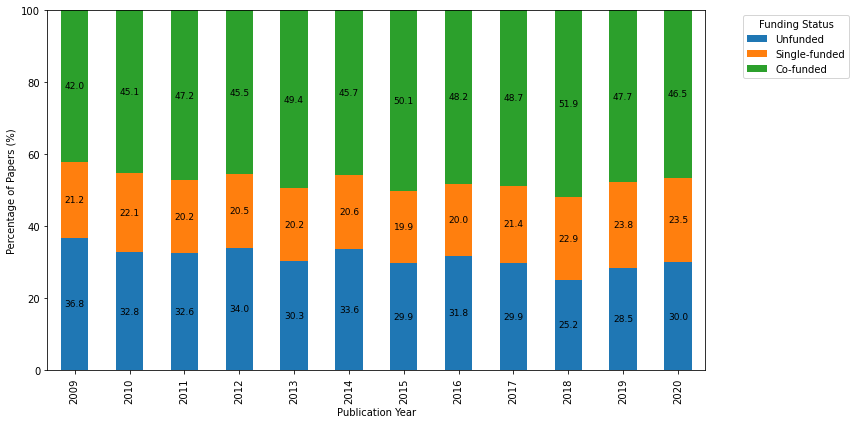

In [16]:
# ============================================================
# Figure 3.2: Stacked Percentage Bar Chart with Labels
# Annual Percentage Distribution of Funding Status
# ============================================================

import matplotlib.pyplot as plt

# Select percentage columns for plotting
plot_pct = annual_pct[
    ["Unfunded", "Single-funded", "Co-funded"]
].copy()

# Create stacked percentage bar chart
ax = plot_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

# ------------------------------------------------------------
# Add percentage labels inside each bar segment
# ------------------------------------------------------------

for i, year in enumerate(plot_pct.index):
    cumulative_height = 0

    for status in ["Unfunded", "Single-funded", "Co-funded"]:
        value = plot_pct.loc[year, status]

        # Label position: middle of each stacked segment
        label_y = cumulative_height + value / 2

        # Add label only when the segment is large enough
        if value >= 3:
            ax.text(
                i,
                label_y,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=9
            )

        cumulative_height += value
        
# ------------------------------------------------------------
# Customize figure
# ------------------------------------------------------------

plt.ylabel("Percentage of Papers (%)")
plt.xlabel("Publication Year")
# plt.title("Figure 3.2. Annual Percentage Distribution of Funding Status")
plt.ylim(0, 100)

plt.legend(
    title="Funding Status",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_2_Stacked_Percentage_Bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_2_Stacked_Percentage_Bar.pdf",
    bbox_inches="tight"
)

plt.show()

3. Funded vs. Unfunded Trend

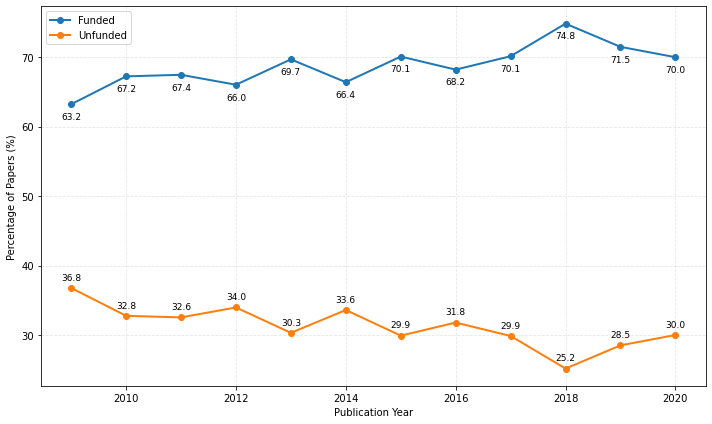

In [18]:
# ============================================================
# Figure 3.3: Funded vs. Unfunded Trend
# with Percentage Labels
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# ------------------------------------------------------------
# Plot lines
# ------------------------------------------------------------

plt.plot(
    annual_pct.index,
    annual_pct["Funded"],
    marker="o",
    linewidth=2,
    label="Funded"
)

plt.plot(
    annual_pct.index,
    annual_pct["Unfunded"],
    marker="o",
    linewidth=2,
    label="Unfunded"
)

# ------------------------------------------------------------
# Add percentage labels
# ------------------------------------------------------------

for year, value in zip(
    annual_pct.index,
    annual_pct["Funded"]
):
    plt.annotate(
        f"{value:.1f}",
        (year, value),
        textcoords="offset points",
        xytext=(0, -15),
        ha="center",
        fontsize=9
    )

for year, value in zip(
    annual_pct.index,
    annual_pct["Unfunded"]
):
    plt.annotate(
        f"{value:.1f}",
        (year, value),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9
    )

# ------------------------------------------------------------
# Figure formatting
# ------------------------------------------------------------

plt.xlabel("Publication Year")
plt.ylabel("Percentage of Papers (%)")

# plt.title(
#     "Figure 3.3. Funded and Unfunded BC Publications Over Time"
# )

plt.legend(loc="upper left")

plt.grid(
    alpha=0.3,
    linestyle="--"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_3_Funded_vs_Unfunded.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_3_Funded_vs_Unfunded.pdf",
    bbox_inches="tight"
)

plt.show()

4. LOESS-Smoothed Funded Trend

In [19]:
import sys

!{sys.executable} -m pip install statsmodels

You should consider upgrading via the 'c:\users\jkimi\appdata\local\programs\python\python37\python.exe -m pip install --upgrade pip' command.


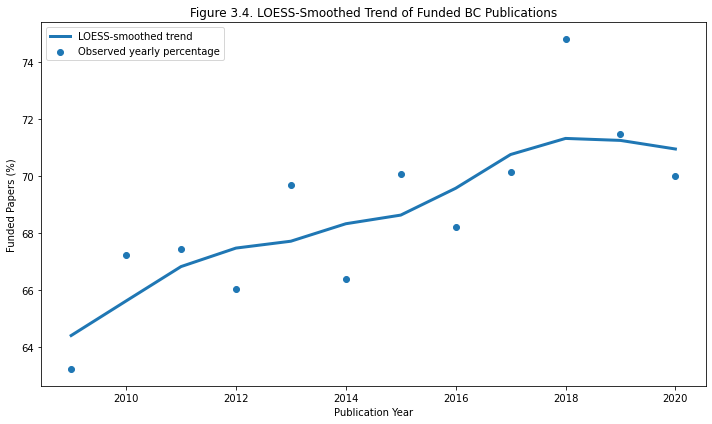

In [20]:
# ============================================================
# Figure 3.4: LOESS-Smoothed Funded Trend
# ============================================================

import statsmodels
from statsmodels.nonparametric.smoothers_lowess import lowess

loess_funded = lowess(
    endog=annual_pct["Funded"],
    exog=annual_pct.index,
    frac=0.5
)

plt.figure(figsize=(10, 6))

plt.scatter(
    annual_pct.index,
    annual_pct["Funded"],
    label="Observed yearly percentage"
)

plt.plot(
    loess_funded[:, 0],
    loess_funded[:, 1],
    linewidth=3,
    label="LOESS-smoothed trend"
)

plt.xlabel("Publication Year")
plt.ylabel("Funded Papers (%)")
plt.title("Figure 3.4. LOESS-Smoothed Trend of Funded BC Publications")
plt.legend()
plt.tight_layout()
plt.show()

5. Single-funded vs. Co-funded

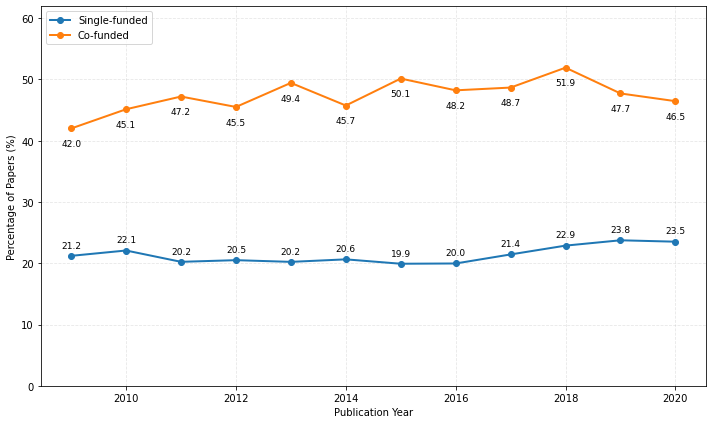

In [21]:
# ============================================================
# Figure 3.5
# Single-funded vs. Co-funded Trend
# with Percentage Labels
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# ------------------------------------------------------------
# Plot lines
# ------------------------------------------------------------

plt.plot(
    annual_pct.index,
    annual_pct["Single-funded"],
    marker="o",
    linewidth=2,
    label="Single-funded"
)

plt.plot(
    annual_pct.index,
    annual_pct["Co-funded"],
    marker="o",
    linewidth=2,
    label="Co-funded"
)

# ------------------------------------------------------------
# Add percentage labels
# ------------------------------------------------------------

for year, value in zip(
    annual_pct.index,
    annual_pct["Single-funded"]
):
    plt.annotate(
        f"{value:.1f}",
        (year, value),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9
    )

for year, value in zip(
    annual_pct.index,
    annual_pct["Co-funded"]
):
    plt.annotate(
        f"{value:.1f}",
        (year, value),
        textcoords="offset points",
        xytext=(0, -18),
        ha="center",
        fontsize=9
    )

# ------------------------------------------------------------
# Figure formatting
# ------------------------------------------------------------

plt.xlabel("Publication Year")
plt.ylabel("Percentage of Papers (%)")

# plt.title(
#     "Figure 3.5. Single-funded and Co-funded BC Publications Over Time"
# )

plt.ylim(
    0,
    max(
        annual_pct["Single-funded"].max(),
        annual_pct["Co-funded"].max()
    ) + 10
)

plt.legend(loc="upper left")

plt.grid(
    alpha=0.3,
    linestyle="--"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_5_Single_vs_Cofunding.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_5_Single_vs_Cofunding.pdf",
    bbox_inches="tight"
)

plt.show()

6. Linear Trend Test

In [22]:
# ============================================================
# Table 3.4: Linear Trend Test
#
# Purpose:
# Estimate the average annual percentage-point change
# for each funding category.
# ============================================================

from scipy.stats import linregress

trend_results = []

for col in [
    "Funded",
    "Unfunded",
    "Single-funded",
    "Co-funded"
]:

    slope, intercept, r_value, p_value, std_err = linregress(
        annual_pct.index,
        annual_pct[col]
    )

    trend_results.append({
        "Funding Category": col,
        "Slope": slope,
        "p-value": p_value,
        "R-squared": r_value ** 2,
        "Standard Error": std_err
    })

trend_table = pd.DataFrame(trend_results)

trend_table["Slope"] = trend_table["Slope"].round(3)
trend_table["p-value"] = trend_table["p-value"].round(4)
trend_table["R-squared"] = trend_table["R-squared"].round(3)
trend_table["Standard Error"] = trend_table["Standard Error"].round(3)

trend_table

,Funding Category,Slope,p-value,R-squared,Standard Error
0,Funded,0.643,0.0030,0.603,0.165
1,Unfunded,-0.643,0.0030,0.603,0.165
2,Single-funded,0.217,0.0551,0.320,0.100
3,Co-funded,0.426,0.0462,0.341,0.187


7. Single-funded vs. Co-funded Trend Visualization

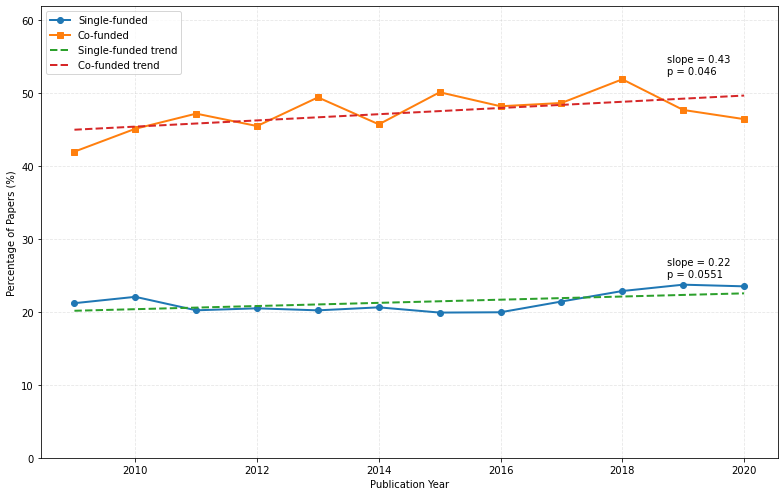

In [26]:
# ============================================================
# Figure 3.5
# Single-funded vs. Co-funded Trend
# with Linear Trend Lines
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

years = annual_pct.index.values

single = annual_pct["Single-funded"].values
cofund = annual_pct["Co-funded"].values

# ------------------------------------------------------------
# Linear Trend: Single-funded
# ------------------------------------------------------------

single_slope, single_intercept, single_r, single_p, single_se = (
    linregress(years, single)
)

single_trend = (
    single_intercept +
    single_slope * years
)

# ------------------------------------------------------------
# Linear Trend: Co-funded
# ------------------------------------------------------------

co_slope, co_intercept, co_r, co_p, co_se = (
    linregress(years, cofund)
)

co_trend = (
    co_intercept +
    co_slope * years
)

# ------------------------------------------------------------
# Create Figure
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

# ------------------------------------------------------------
# Observed Single-funded
# ------------------------------------------------------------

plt.plot(
    years,
    single,
    marker="o",
    linewidth=2,
    label="Single-funded"
)

# ------------------------------------------------------------
# Observed Co-funded
# ------------------------------------------------------------

plt.plot(
    years,
    cofund,
    marker="s",
    linewidth=2,
    label="Co-funded"
)

# ------------------------------------------------------------
# Trend Line: Single-funded
# ------------------------------------------------------------

plt.plot(
    years,
    single_trend,
    linestyle="--",
    linewidth=2,
    label=f"Single-funded trend"
    #     label=f"Single-funded trend (p={single_p:.4f})"
)

plt.text(
    0.85,
    0.40,
    f"slope = {single_slope:.2f}\n"
    f"p = {single_p:.4f}",
    transform=plt.gca().transAxes
)

# ------------------------------------------------------------
# Trend Line: Co-funded
# ------------------------------------------------------------

plt.plot(
    years,
    co_trend,
    linestyle="--",
    linewidth=2,
    label=f"Co-funded trend"
#     label=f"Co-funded trend (p={co_p:.3f})"

)

plt.text(
    0.85,
    0.85,
    f"slope = {co_slope:.2f}\n"
    f"p = {co_p:.3f}",
    transform=plt.gca().transAxes
)

# ------------------------------------------------------------
# Add labels: Single-funded
# ------------------------------------------------------------

# for year, value in zip(years, single):

#     plt.annotate(
#         f"{value:.1f}",
#         (year, value),
#         textcoords="offset points",
#         xytext=(0, 10),
#         ha="center",
#         fontsize=9
#     )

# ------------------------------------------------------------
# Add labels: Co-funded
# ------------------------------------------------------------

# for year, value in zip(years, cofund):

#     plt.annotate(
#         f"{value:.1f}",
#         (year, value),
#         textcoords="offset points",
#         xytext=(0, -15),
#         ha="center",
#         fontsize=9
#     )

# ------------------------------------------------------------
# Figure formatting
# ------------------------------------------------------------

plt.xlabel("Publication Year")

plt.ylabel("Percentage of Papers (%)")

# plt.title(
#     "Figure 3.5. Trends in Single-funded and Co-funded BC Publications"
# )

plt.grid(
    alpha=0.3,
    linestyle="--"
)

plt.ylim(
    0,
    max(
        annual_pct["Single-funded"].max(),
        annual_pct["Co-funded"].max()
    ) + 10
)

plt.legend(loc="upper left")

plt.tight_layout()

# ------------------------------------------------------------
# Save Figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_5_Single_vs_Cofunding_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_5_Single_vs_Cofunding_Trend.pdf",
    bbox_inches="tight"
)

plt.show()

8. Funded vs. Unfunded Trend Trend Visualization

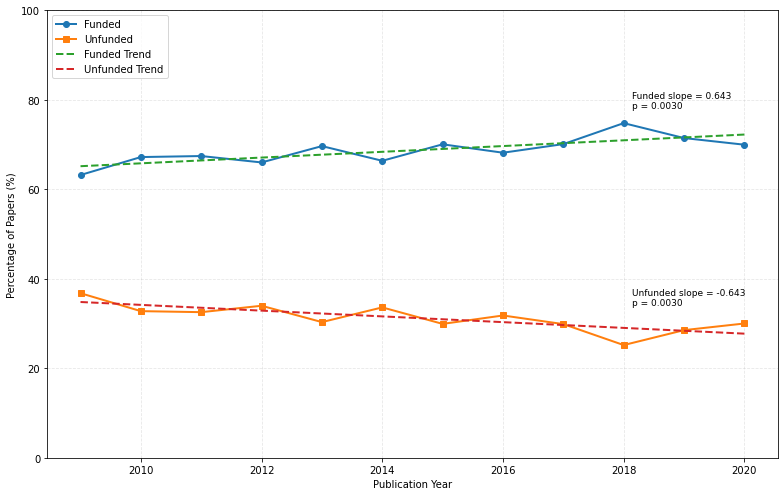

Funded
Slope = 0.643
p-value = 0.0030

Unfunded
Slope = -0.643
p-value = 0.0030


In [29]:
# ============================================================
# Figure 3.3
# Funded vs. Unfunded Trend
# with Percentage Labels and Linear Trend Lines
# ============================================================

import matplotlib.pyplot as plt
from scipy.stats import linregress

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

years = annual_pct.index.values

funded = annual_pct["Funded"].values
unfunded = annual_pct["Unfunded"].values

# ------------------------------------------------------------
# Linear Trend: Funded
# ------------------------------------------------------------

funded_slope, funded_intercept, funded_r, funded_p, funded_se = (
    linregress(years, funded)
)

funded_trend = (
    funded_intercept +
    funded_slope * years
)

# ------------------------------------------------------------
# Linear Trend: Unfunded
# ------------------------------------------------------------

unfunded_slope, unfunded_intercept, unfunded_r, unfunded_p, unfunded_se = (
    linregress(years, unfunded)
)

unfunded_trend = (
    unfunded_intercept +
    unfunded_slope * years
)

# ------------------------------------------------------------
# Create Figure
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

# ------------------------------------------------------------
# Observed Funded
# ------------------------------------------------------------

plt.plot(
    years,
    funded,
    marker="o",
    linewidth=2,
    label="Funded"
)

# ------------------------------------------------------------
# Observed Unfunded
# ------------------------------------------------------------

plt.plot(
    years,
    unfunded,
    marker="s",
    linewidth=2,
    label="Unfunded"
)

# ------------------------------------------------------------
# Funded Trend Line
# ------------------------------------------------------------

plt.plot(
    years,
    funded_trend,
    linestyle="--",
    linewidth=2,
    label=f"Funded Trend"
#     label=f"Funded Trend (p={funded_p:.3f})"
)

# ------------------------------------------------------------
# Unfunded Trend Line
# ------------------------------------------------------------

plt.plot(
    years,
    unfunded_trend,
    linestyle="--",
    linewidth=2,
    label=f"Unfunded Trend"
#     label=f"Unfunded Trend (p={unfunded_p:.3f})"
)

# ------------------------------------------------------------
# Add Percentage Labels: Funded
# ------------------------------------------------------------

# for year, value in zip(years, funded):

#     plt.annotate(
#         f"{value:.1f}",
#         (year, value),
#         textcoords="offset points",
#         xytext=(0, -15),
#         ha="center",
#         fontsize=9
#     )

# ------------------------------------------------------------
# Add Percentage Labels: Unfunded
# ------------------------------------------------------------

# for year, value in zip(years, unfunded):

#     plt.annotate(
#         f"{value:.1f}",
#         (year, value),
#         textcoords="offset points",
#         xytext=(0, 8),
#         ha="center",
#         fontsize=9
#     )

# ------------------------------------------------------------
# Add Slope and p-value Information
# ------------------------------------------------------------

plt.text(
    0.80,
    0.82,
    f"Funded slope = {funded_slope:.3f}\n"
    f"p = {funded_p:.4f}",
    transform=plt.gca().transAxes,
    fontsize=9,
    verticalalignment="top"
)

plt.text(
    0.80,
    0.38,
    f"Unfunded slope = {unfunded_slope:.3f}\n"
    f"p = {unfunded_p:.4f}",
    transform=plt.gca().transAxes,
    fontsize=9,
    verticalalignment="top"
)

# ------------------------------------------------------------
# Figure Formatting
# ------------------------------------------------------------

plt.xlabel("Publication Year")

plt.ylabel("Percentage of Papers (%)")

# plt.title(
#     "Figure 3.3. Funded and Unfunded BC Publications Over Time"
# )

plt.ylim(0, 100)

plt.grid(
    alpha=0.3,
    linestyle="--"
)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

plt.legend(
    loc="upper left",
    frameon=True
)

plt.tight_layout()

# ------------------------------------------------------------
# Save Figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_3_Funded_vs_Unfunded_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_3_Funded_vs_Unfunded_Trend.pdf",
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Print Statistics for Reporting
# ------------------------------------------------------------

print("Funded")
print(f"Slope = {funded_slope:.3f}")
print(f"p-value = {funded_p:.4f}")

print("\nUnfunded")
print(f"Slope = {unfunded_slope:.3f}")
print(f"p-value = {unfunded_p:.4f}")

9. Annual Distribution of Funding Status in BC (Absolute count)

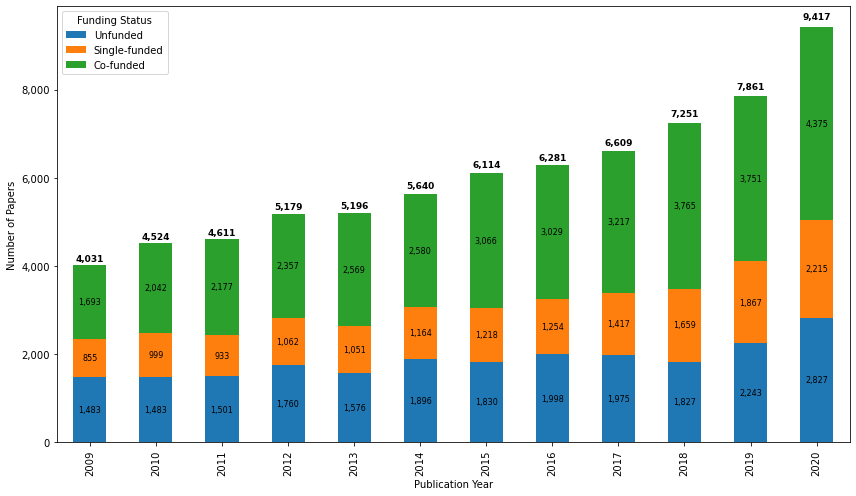

In [30]:
# ============================================================
# Figure 3.1
# Annual Distribution of Funding Status in BC Publications
# (Absolute Counts)
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

plot_counts = annual_counts[
    [
        "Unfunded",
        "Single-funded",
        "Co-funded"
    ]
]

# ------------------------------------------------------------
# Create Figure
# ------------------------------------------------------------

ax = plot_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

# ------------------------------------------------------------
# Add count labels
# ------------------------------------------------------------

for i, year in enumerate(plot_counts.index):

    cumulative_height = 0

    for status in [
        "Unfunded",
        "Single-funded",
        "Co-funded"
    ]:

        value = plot_counts.loc[year, status]

        if value > 0:

            ax.text(
                i,
                cumulative_height + value / 2,
                f"{int(value):,}",
                ha="center",
                va="center",
                fontsize=8
            )

        cumulative_height += value

# ------------------------------------------------------------
# Add total paper counts
# ------------------------------------------------------------

for i, year in enumerate(plot_counts.index):

    total = annual_counts.loc[year, "Total Papers"]

    ax.text(
        i,
        total + total * 0.02,
        f"{int(total):,}",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Figure formatting
# ------------------------------------------------------------

plt.xlabel("Publication Year")

plt.ylabel("Number of Papers")

from matplotlib.ticker import StrMethodFormatter

ax.yaxis.set_major_formatter(
    StrMethodFormatter('{x:,.0f}')
)

# plt.title(
#     "Figure 3.1. Annual Distribution of Funding Status in BC Publications"
# )

plt.legend(
    title="Funding Status",
    loc="upper left",
    frameon=True
)

plt.tight_layout()

# ------------------------------------------------------------
# Save Figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_1_Funding_Status_Counts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_1_Funding_Status_Counts.pdf",
    bbox_inches="tight"
)

plt.show()